In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.multiclass import OneVsRestClassifier
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

# set prints off
mask.prints = True

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


## Analysis stage: IIVV selection (only)

- `mask.IIVV_mask("vv_long_across")`
- `mask.IIVV_mask("vv_long_across_extended")`
- `mask.IIVV_mask("vv_medium_across_extended")`
- `mask.IIVV_mask("vv_distance_close_skip_1")`

In [6]:
# load masking selection
Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    ###
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

In [7]:
print(len(Mask_sel))

13


In [8]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

All 	 all
Long a+ 	 vv_long_across
Long a+ ext. 	 vv_long_across_extended
Med. a+ ext. 	 vv_medium_across_extended
Skip1 close 	 vv_distance_close_skip_1
Adj. close 	 adjacent_close
Med. adj. 	 vv_distance_medium_adj
Adj. far 	 adjacent_far
Skip1 medium 	 skip1_medium
Skip1 far 	 skip1_far
Opp. close 	 opposite_close
Opp. medium 	 opposite_medium
Opp. far 	 opposite_far


In [9]:
results = []
numXparams = []
n_trials = 10

for Mname, Msel in Mask_sel.items():
    if Msel == "all":
        X_tmp = X[:, :, :]
    else:
        # apply mask
        mask.IIVV_mask(Msel, plot=False)
        X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(n_trials):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params.csv", index=False)

Trial: 0 
	 All
Train patients: [48 29 46 27  7 45 51 78 86 81 91 90  3 69 88 30 20 57 58 85 66 62 44  4
 16 19 43 41  6 89 56  0 37 31 53 12 38 25 55 11 34 75 60 79  1 35 84 15
 72 21 32 52 96 97 73 22 92 76 28 40 49 42 68 61 13 74 39 23 87 10 95 70
 67 50 47]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24 77]
Trial: 1 
	 All
Train patients: [41 55 52 21 92 99 38 36 58 73 68 56 39 57 59 25 37 84 49 65 16 81 89 29
 97 46 61  4 96 23 85  3 86 33 62 45 50 54 74 27  9 19 63  0 88 60 24 64
 66  8 95 14 72 91 15 32 31 12 20 22 53 28  7 75 80  1 18 67 83  6 79 10
 76 13 40]
Test patients: [43 34 48 90 87 51 70 47 82 78 69 30 77 94 35 44 42 11  2]
Trial: 2 
	 All
Train patients: [69 12 83 33 32  6 75 59 99 85  1 20 27 47 38 63  7 51 89 11 13 77 68 94
 35 21 65 74 56 10 95 19 60 58 44 64 48 67  9 73 81 88 97 29 87 53 55 84
 49 72 80 61 36 41 54 45  4 70 42 40 22 34 66 50 91 52 37  8 79 86 46 24
 76 16 43]
Test patients: [39 31 57 25 18 82  2 28 92 14 62 90 78 15  0 23  3

In [80]:
# df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
# df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

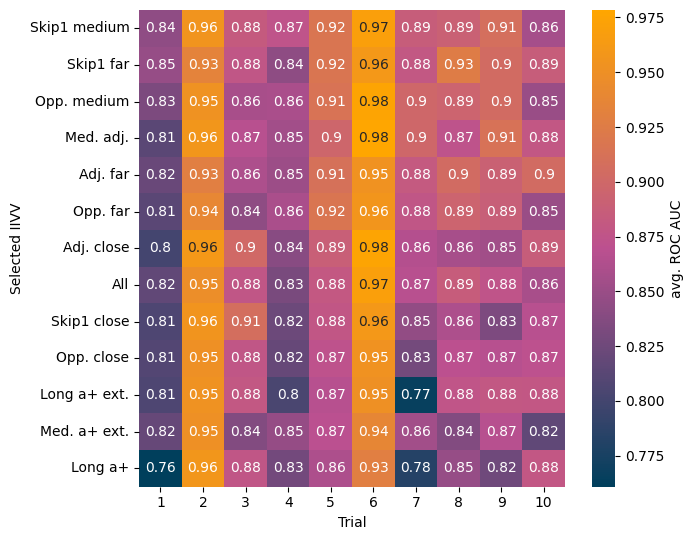

In [81]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)

fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "avg. ROC AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [82]:
df_pivot

Trial,1,2,3,4,5,6,7,8,9,10
Mask,,,,,,,,,,
Skip1 medium,0.843478,0.955026,0.882716,0.874510,0.916667,0.969136,0.886473,0.890093,0.908333,0.856618
Skip1 far,0.847826,0.933862,0.876543,0.843137,0.916667,0.959877,0.879227,0.925697,0.904167,0.886029
Opp. medium,0.832609,0.952381,0.858025,0.858824,0.913889,0.975309,0.898551,0.894737,0.904167,0.849265
Med. adj.,0.813043,0.957672,0.867284,0.854902,0.897222,0.978395,0.898551,0.873065,0.912500,0.878676
Adj. far,0.821739,0.928571,0.861111,0.850980,0.911111,0.953704,0.881643,0.904025,0.891667,0.904412
Opp. far,0.813043,0.939153,0.842593,0.858824,0.916667,0.956790,0.876812,0.894737,0.887500,0.849265
Adj. close,0.800000,0.960317,0.901235,0.839216,0.888889,0.975309,0.864734,0.857585,0.854167,0.886029
All,0.817391,0.947090,0.876543,0.831373,0.880556,0.969136,0.867150,0.885449,0.875000,0.858456
Skip1 close,0.806522,0.955026,0.907407,0.823529,0.877778,0.959877,0.845411,0.860681,0.833333,0.867647


In [83]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Skip1 medium    0.898305
Skip1 far       0.897303
Opp. medium     0.893775
Med. adj.       0.893131
Adj. far        0.890896
Opp. far        0.883538
Adj. close      0.882748
All             0.880814
Skip1 close     0.873721
Opp. close      0.871697
Long a+ ext.    0.865944
Med. a+ ext.    0.863432
Long a+         0.854724
dtype: float64


In [84]:
df_plot

,Mask,n_params,avg. ROC AUC
0,All,239568,0.880814
1,Long a+,496,0.854724
2,Long a+ ext.,3720,0.865944
3,Med. a+ ext.,3720,0.863432
4,Skip1 close,11160,0.873721
5,Adj. close,9052,0.882748
6,Med. adj.,11997,0.893131
7,Adj. far,20460,0.890896
8,Skip1 medium,13640,0.898305
9,Skip1 far,6944,0.897303


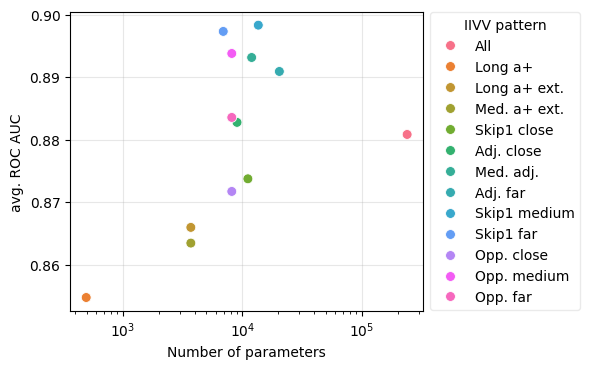

In [85]:
fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    # palette="dark:salmon_r",
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Number of parameters")
ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Take heuristically selected IIVV pattern

In [ ]:
# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "All": "all",
}

In [ ]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

In [ ]:
results = []
numXparams = []
for Mname, Msel in Mask_sel.items():
    mask.IIVV_mask(Msel, plot=False)
    # apply mask
    X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(7):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params.csv", index=False)

In [ ]:
# df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
# df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

In [ ]:
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = [
    "Long a+",
    "Long a+ ext.",
    "Med. a+ ext.",
    "Skip1 close",
    "All",
]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "avg. ROC AUC"}, ax=ax0
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Mask"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.set_xscale("log")
# ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

ax1.legend(title="IIVV selection", framealpha=0.4)
plt.savefig(f"results/IIVV_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

___